# Week 4: Exploratory Data Analysis (EDA)
## Project: Moneyball – IPL Player Valuation
### Team 05 | Data Science and Visualization

## 1. Introduction

Exploratory Data Analysis (EDA) is the process of examining and visualizing datasets to understand their structure, distributions, patterns, and relationships.

In this project, EDA is used to explore IPL auction prices, batting performance, bowling performance, and match data to identify patterns related to player valuation.

## 2. Objectives

- Understand the distribution of IPL auction prices.
- Explore batting and bowling performance statistics.
- Identify patterns and relationships between variables.
- Use visualizations to communicate important findings.
- Generate insights that may help explain differences in player auction prices.

## 3. Importing Required Libraries

Pandas and NumPy are used for data handling and numerical operations. Matplotlib and Seaborn are used to create visualizations for exploratory analysis.

In [11]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Required libraries imported successfully!")

Required libraries imported successfully!


## 4. Loading the Datasets

The project uses four datasets: IPL auction records, top batsmen statistics, top bowlers statistics, and match records.

These datasets will be used to explore player valuation and performance patterns.

In [12]:
data_folder = r"D:\DSD\College\DSV\Project\archive\moneyball\datasets"

auction = pd.read_excel(os.path.join(data_folder, "Auction.xlsx"))
batsmen = pd.read_excel(os.path.join(data_folder, "Top_100_batsman.xlsx"))
bowlers = pd.read_excel(os.path.join(data_folder, "Top_100_bowlers.xlsx"))
matches = pd.read_csv(os.path.join(data_folder, "matches.csv"))

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


## 5. Dataset Overview

Before performing exploratory data analysis, it is important to understand the size and structure of each dataset. This helps us identify the available variables and select suitable data for visualization.

The four datasets used in this project are:
- **Auction Dataset:** Contains player auction details, teams, prices, and years.
- **Top 100 Batsmen Dataset:** Contains batting performance statistics.
- **Top 100 Bowlers Dataset:** Contains bowling performance statistics.
- **Matches Dataset:** Contains IPL match results and related details.

### 5.1 Dataset Dimensions

The dimensions of a dataset indicate the number of rows and columns. This helps us understand the amount of data available for analysis.

In [13]:
datasets = {
    "Auction": auction,
    "Top 100 Batsmen": batsmen,
    "Top 100 Bowlers": bowlers,
    "Matches": matches
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows and {data.shape[1]} columns")

Auction: 56 rows and 5 columns
Top 100 Batsmen: 100 rows and 14 columns
Top 100 Bowlers: 100 rows and 13 columns
Matches: 756 rows and 18 columns


### 5.2 Column Names and Data Types

Examining column names and data types helps us understand the information stored in each dataset. It also helps identify variables that may need conversion before visualization.

In [14]:
for name, data in datasets.items():
    print(f"\n--- {name} ---")
    print("Columns:", data.columns.tolist())
    print("\nData types:")
    print(data.dtypes)


--- Auction ---
Columns: ['TEAM', 'PLAYER', 'TYPE', 'PRICE(In crore Indian Rupees) ', 'YEAR']

Data types:
TEAM                                  str
PLAYER                                str
TYPE                                  str
PRICE(In crore Indian Rupees)     float64
YEAR                                int64
dtype: object

--- Top 100 Batsmen ---
Columns: ['POS', 'PLAYER', 'Mat', 'Inns', 'NO', 'Runs', 'HS', 'Avg', 'BF', 'SR', 100, 50, '4s', '6s']

Data types:
POS         int64
PLAYER        str
Mat         int64
Inns        int64
NO          int64
Runs        int64
HS         object
Avg       float64
BF          int64
SR        float64
100         int64
50          int64
4s          int64
6s          int64
dtype: object

--- Top 100 Bowlers ---
Columns: ['POS', 'PLAYER', 'Mat', 'Inns', 'Ov', 'Runs', 'Wkts', 'BBI', 'Avg', 'Econ', 'SR', '4w', '5w']

Data types:
POS         int64
PLAYER        str
Mat         int64
Inns        int64
Ov        float64
Runs        int64
Wkts        

## 5.3 Univariate Analysis

Univariate analysis examines one variable at a time to understand its distribution, central tendency, and spread.

In this section, we analyse IPL auction prices using a histogram and descriptive statistics.

Auction Price Summary:
count    56.000000
mean      7.636607
std       3.295155
min       3.000000
25%       5.000000
50%       7.000000
75%       9.525000
max      16.000000
Name: PRICE(In crore Indian Rupees) , dtype: float64


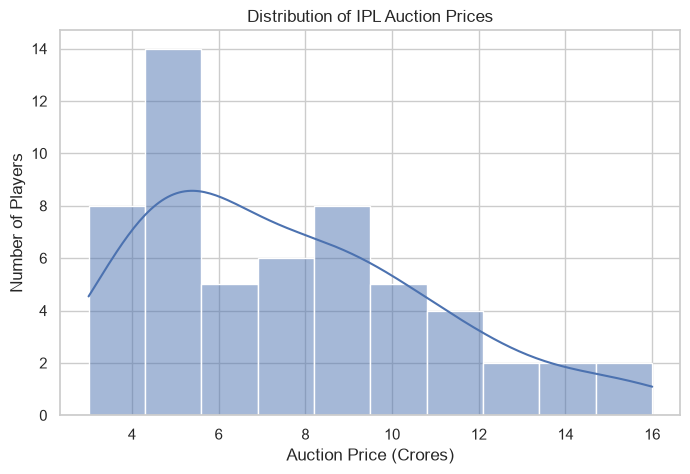

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

price_col = "PRICE(In crore Indian Rupees) "

print("Auction Price Summary:")
print(auction[price_col].describe())

plt.figure(figsize=(8, 5))
sns.histplot(data=auction, x=price_col, bins=10, kde=True)

plt.title("Distribution of IPL Auction Prices")
plt.xlabel("Auction Price (Crores)")
plt.ylabel("Number of Players")
plt.show()

## 5.4 Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

In this section, we compare balls faced and runs scored among the top 100 batsmen to explore how these batting variables are associated.

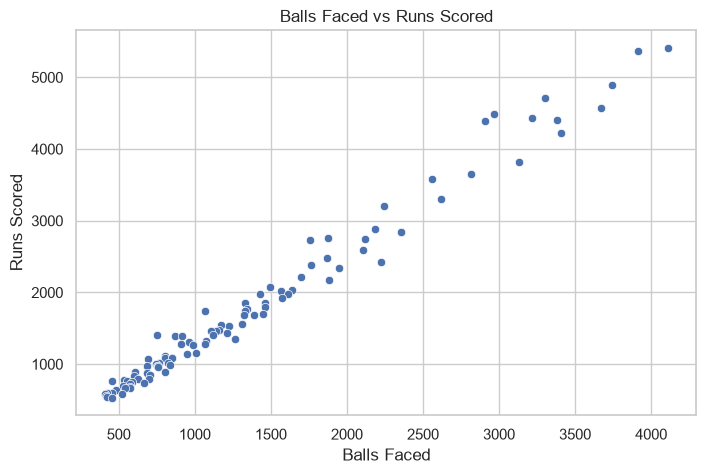

Correlation between Balls Faced and Runs:
0.9898409347639906


In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=batsmen,
    x="BF",
    y="Runs"
)

plt.title("Balls Faced vs Runs Scored")
plt.xlabel("Balls Faced")
plt.ylabel("Runs Scored")
plt.show()

print("Correlation between Balls Faced and Runs:")
print(batsmen["BF"].corr(batsmen["Runs"]))

## 5.5 Bowling Performance Analysis

This section explores the relationship between overs bowled and wickets taken among the top 100 bowlers.

A scatter plot and correlation coefficient are used to examine the strength and direction of the relationship.

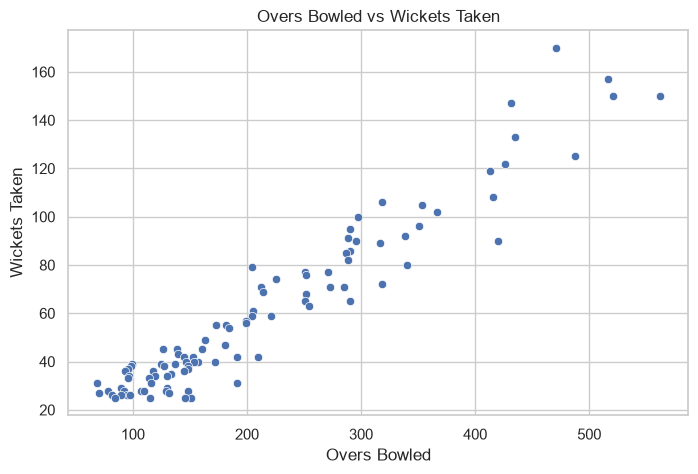

Correlation between Overs and Wickets:
0.9596815866522057


In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=bowlers,
    x="Ov",
    y="Wkts"
)

plt.title("Overs Bowled vs Wickets Taken")
plt.xlabel("Overs Bowled")
plt.ylabel("Wickets Taken")
plt.show()

print("Correlation between Overs and Wickets:")
print(bowlers["Ov"].corr(bowlers["Wkts"]))

## 6. Key Findings and Interpretation

### 6.1 Auction Price Distribution
- Auction prices vary considerably across the selected players.
- The average auction price is approximately ₹7.64 crore.
- The maximum recorded auction price is ₹16 crore.

### 6.2 Batting Performance
- Balls faced and runs scored show a strong positive correlation.
- The correlation coefficient is approximately 0.989.
- Players who faced more balls generally scored more runs in this dataset.

### 6.3 Bowling Performance
- Overs bowled and wickets taken show a strong positive correlation.
- The correlation coefficient is approximately 0.960.
- Bowlers who bowled more overs generally took more wickets in this dataset.

## 7. Conclusion

The exploratory data analysis revealed patterns in IPL auction prices,
batting performance, and bowling performance. These initial findings
will help guide further investigation into player valuation.

Correlation indicates association and does not establish causation.
Further analysis is required to examine the relationship between
player performance and auction price.